In [17]:
import sys, os
sys.path.append(os.path.abspath('..'))

In [5]:
from agent.graph import build_graph
agent = build_graph()
for chunk in agent.stream(
    {"question": "tell me more about the order 47770eb9100c2d0c44946d9cf07ec65d"},
    stream_mode="updates", subgraphs= True
):
    print(chunk)

((), {'planner': {'plan': Plan(subquestions=[SubQuestion(id='q1', question='Retrieve details for order 47770eb9100c2d0c44946d9cf07ec65d, including status, purchase and delivery timestamps, estimated delivery date, customer location, purchased items and sellers, item prices and freight charges, and payment details.', agent='query', depends_on=[])])}})
((), {'orchestrator': {'ready_tasks': [SubQuestion(id='q1', question='Retrieve details for order 47770eb9100c2d0c44946d9cf07ec65d, including status, purchase and delivery timestamps, estimated delivery date, customer location, purchased items and sellers, item prices and freight charges, and payment details.', agent='query', depends_on=[])]}})
(('query_worker:83627ffd-fc03-3571-7406-6b96b10e89a0',), {'query_agent': {'messages': [{'role': 'system', 'content': '\nYou are the Query Agent in a multi-agent Olist e-commerce AI system.\n\nYour job is to complete ONLY the database-related task assigned to you.\n\nYou have access to:\n\n1. Speciali

In [8]:
import joblib
from pathlib import Path

MODEL_PATH = Path("../artifacts/models/final_model.pkl")

pipeline = joblib.load(MODEL_PATH)

print("Pipeline type:", type(pipeline))
print("Pipeline steps:", pipeline.named_steps.keys())

preprocessor = pipeline.named_steps["preprocessor"]
model = pipeline.named_steps["best_model"]

print("Model type:", type(model))
print("Model classes:", getattr(model, "classes_", None))

try:
    print("Transformed feature names:")
    print(preprocessor.get_feature_names_out())
except Exception as e:
    print("Could not get feature names:", e)

Pipeline type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: dict_keys(['preprocessor', 'best_model'])
Model type: <class 'xgboost.sklearn.XGBClassifier'>
Model classes: [0 1]
Transformed feature names:
['num__number_of_items' 'num__number_of_products' 'num__number_of_sellers'
 'num__total_price' 'num__total_freight' 'num__total_product_weight'
 'num__total_product_volume' 'num__total_payment_value'
 'num__max_payment_installments' 'num__number_of_payments'
 'num__order_purchase_hour' 'num__order_purchase_day_of_week'
 'num__order_purchase_month' 'num__order_purchase_year'
 'num__order_approval_delay_hours' 'num__estimated_delivery_days'
 'cat__customer_state_AC' 'cat__customer_state_AL'
 'cat__customer_state_AM' 'cat__customer_state_AP'
 'cat__customer_state_BA' 'cat__customer_state_CE'
 'cat__customer_state_DF' 'cat__customer_state_ES'
 'cat__customer_state_GO' 'cat__customer_state_MA'
 'cat__customer_state_MG' 'cat__customer_state_MS'
 'cat__customer_state_MT' 'cat__customer_s

In [15]:


import shap
import pandas as pd
import numpy as np




# 3. Load one real row of data.
# Replace this path with your actual processed dataset.
df = pd.read_csv("../data/processed/processed.csv")

# Replace this with the original input features used by
# your prediction pipeline, excluding the target column.
input_df = df.drop(columns=["is_late"]).iloc[[0]]

# 4. Transform the input using the saved preprocessor
X_transformed = preprocessor.transform(input_df)

feature_names = preprocessor.get_feature_names_out()

# XGBoost generally works well with a dense DataFrame here.
# Preserve the transformed feature names.
if hasattr(X_transformed, "toarray"):
    X_transformed = X_transformed.toarray()

X_transformed = pd.DataFrame(
    X_transformed,
    columns=feature_names,
)

# 5. Create the SHAP explainer
explainer = shap.TreeExplainer(model)

# 6. Calculate SHAP values
shap_values = explainer(X_transformed)
print((shap_values))
print("Transformed shape:", X_transformed.shape)
print("SHAP shape:", shap_values.values.shape)

# 7. Rank the features by absolute contribution
values = np.asarray(shap_values.values)

if values.ndim != 2 or values.shape[0] != 1:
    raise ValueError(
        f"Unexpected SHAP output shape: {values.shape}"
    )

contributions = pd.DataFrame({
    "feature": feature_names,
    "shap_value": values[0],
})

contributions["absolute_impact"] = (
    contributions["shap_value"].abs()
)

contributions = contributions.sort_values(
    "absolute_impact",
    ascending=False,
)

print("\nTop 10 contributing features:")
print(contributions.head(10).to_string(index=False))


.values =
array([[ 1.42986719e-02,  1.79442181e-03,  6.81367144e-03,
        -3.12374290e-02, -4.15992230e-01, -2.32547335e-02,
        -1.75579898e-02, -6.36927262e-02,  2.22453638e-03,
        -7.27625447e-05, -6.93407133e-02, -1.11853350e-02,
        -4.23629642e-01, -1.65090322e-01, -7.11180568e-02,
         2.14124992e-01,  0.00000000e+00, -9.36433300e-03,
        -2.20692109e-05,  0.00000000e+00, -2.42847186e-02,
        -3.10625648e-03,  8.75451416e-03, -1.71266997e-03,
         1.92904670e-03, -8.47449433e-03,  9.61071625e-02,
        -3.98659240e-03,  1.54897163e-03, -6.27690414e-03,
        -3.61000327e-03, -5.02317399e-03, -1.57373399e-03,
         2.35945117e-02,  1.04202695e-01, -1.79986551e-03,
         2.23210285e-04, -1.49007872e-04,  8.50278419e-03,
        -1.75112172e-03, -1.07727968e-03,  1.51638061e-01,
        -5.18978573e-04,  0.00000000e+00,  8.91571864e-04,
         0.00000000e+00,  2.70015851e-04, -1.07655051e-05,
         4.09203989e-04, -9.31665953e-03,  4.8

In [12]:
# Predict probabilities using the complete saved pipeline
late_probability = pipeline.predict_proba(input_df)[0, 1]

print(f"Late-delivery probability: {late_probability:.2%}")
print(f"Predicted class: {pipeline.predict(input_df)[0]}")
print(f"Actual class: {df['is_late'].iloc[0]}")

Late-delivery probability: 34.70%
Predicted class: 0
Actual class: 0


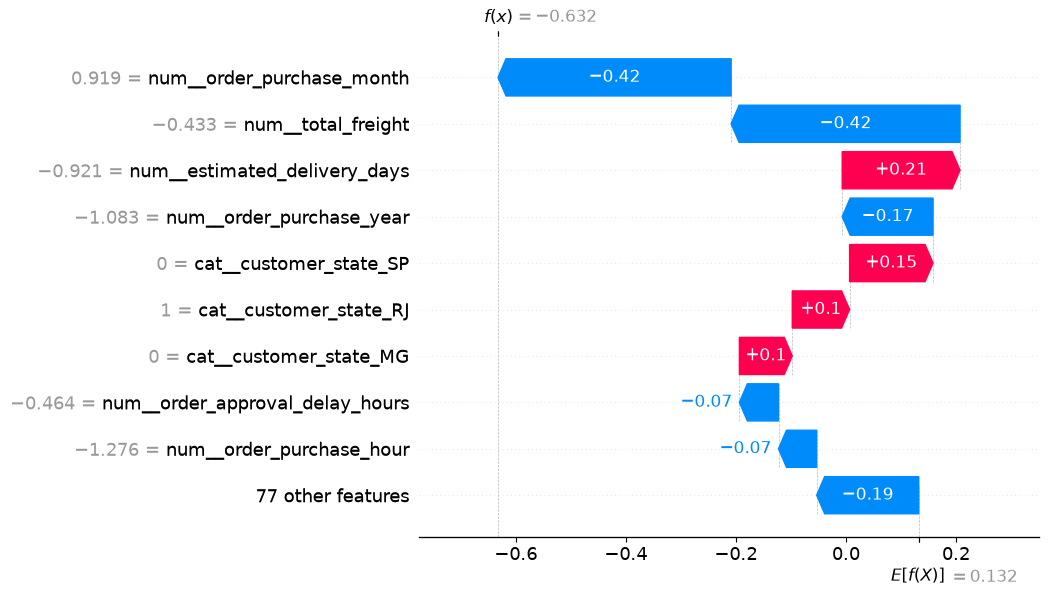

<Figure size 640x480 with 0 Axes>

In [13]:
import matplotlib.pyplot as plt

shap.plots.waterfall(shap_values[0], max_display=10)
plt.tight_layout()
plt.show()

Model probability: 0.34696934
SHAP baseline: 0.35729509982832075
Baseline + contributions: 0.3469693215201965


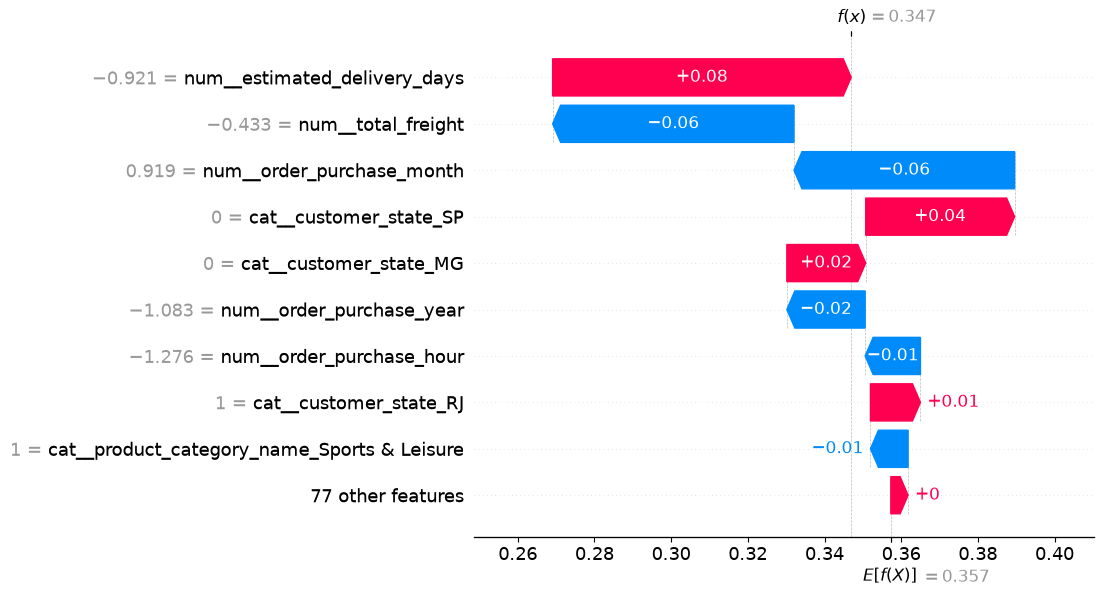

<Figure size 640x480 with 0 Axes>

In [14]:
# Prepare a representative background sample.
# For final use, prefer X_train before preprocessing.
background_df = (
    df.drop(columns=["is_late"])
    .sample(n=min(100, len(df)), random_state=42)
)

background_transformed = preprocessor.transform(background_df)

if hasattr(background_transformed, "toarray"):
    background_transformed = background_transformed.toarray()

background_transformed = pd.DataFrame(
    background_transformed,
    columns=feature_names,
)

# Explain probabilities rather than raw margins.
probability_explainer = shap.TreeExplainer(
    model,
    data=background_transformed,
    feature_perturbation="interventional",
    model_output="probability",
)

probability_shap_values = probability_explainer(
    X_transformed
)

print("Model probability:", pipeline.predict_proba(input_df)[0, 1])
print("SHAP baseline:", probability_shap_values.base_values[0])
print(
    "Baseline + contributions:",
    probability_shap_values.base_values[0]
    + probability_shap_values.values[0].sum()
)

shap.plots.waterfall(
    probability_shap_values[0],
    max_display=10,
)
plt.tight_layout()
plt.show()

In [ ]:

import json
from pathlib import Path

import joblib
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
)


# Project paths
ROOT = Path(__file__).resolve().parent
MODEL_PATH = ROOT / "artifacts" / "models" / "final_model.pkl"
X_TEST_PATH = ROOT / "data" / "test" / "x_test.npy"
Y_TEST_PATH = ROOT / "data" / "test" / "y_test.npy"
OUTPUT_PATH = ROOT / "artifacts" / "evaluation_metrics.json"

# Load the fitted model and test data
model = joblib.load(MODEL_PATH)
X_test = np.load(X_TEST_PATH, allow_pickle=False)
y_test = np.load(Y_TEST_PATH, allow_pickle=False).ravel()

# Generate predictions
y_pred = model.predict(X_test)

# Calculate probabilities for ROC-AUC
y_proba = model.predict_proba(X_test)[:, 1]

# Compute metrics
metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(
        precision_score(y_test, y_pred, zero_division=0)
    ),
    "recall": float(
        recall_score(y_test, y_pred, zero_division=0)
    ),
    "f1_score": float(
        f1_score(y_test, y_pred, zero_division=0)
    ),
    "f2_score": float(
        fbeta_score(y_test, y_pred, beta=2, zero_division=0)
    ),
    "roc_auc": float(roc_auc_score(y_test, y_proba)),
}

print("\n=== Evaluation Metrics ===")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, zero_division=0))

print("\n=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

# Save the metrics
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_PATH, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

print(f"\nMetrics saved to: {OUTPUT_PATH}")


NameError: name '__file__' is not defined

In [20]:
from pathlib import Path

print("Current directory:", Path.cwd())

for path in [
    "./artifacts/models/final_model.pkl",
    "./artifacts/data/test/x_test.npy",
    "./artifacts/data/test/y_test.npy",
]:
    print(path, "->", Path(path).exists())

Current directory: c:\Users\User\Documents\ai_and_ml_with_gen_ai_proj\agent
./artifacts/models/final_model.pkl -> False
./artifacts/data/test/x_test.npy -> False
./artifacts/data/test/y_test.npy -> False


In [21]:

import json
import joblib
import numpy as np
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)



# Go one level up from the agent folder
ROOT = Path.cwd().parent

MODEL_PATH = ROOT / "artifacts" / "models" / "final_model.pkl"
X_TEST_PATH = ROOT / "artifacts" / "data" / "test" / "x_test.npy"
Y_TEST_PATH = ROOT / "artifacts" / "data" / "test" / "y_test.npy"
OUTPUT_PATH = ROOT / "artifacts" / "metrics" / "metrics.json"

# Verify all paths
for path in [MODEL_PATH, X_TEST_PATH, Y_TEST_PATH]:
    print(f"{path} -> {path.exists()}")

# 2. Load model and test data
model = joblib.load(MODEL_PATH)
X_test = np.load(X_TEST_PATH)
y_test = np.load(Y_TEST_PATH).ravel()

# 3. Generate predictions
y_pred = model.predict(X_test)

# 4. Calculate evaluation metrics
metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "f1_score": float(f1_score(y_test, y_pred, zero_division=0)),
    "f2_score": float(fbeta_score(y_test, y_pred, beta=2, zero_division=0)),
}

# Calculate ROC-AUC when probability estimates are available
if hasattr(model, "predict_proba"):
    y_proba = model.predict_proba(X_test)[:, 1]
    metrics["roc_auc"] = float(roc_auc_score(y_test, y_proba))
elif hasattr(model, "decision_function"):
    y_scores = model.decision_function(X_test)
    metrics["roc_auc"] = float(roc_auc_score(y_test, y_scores))

# 5. Display metrics
print("=" * 45)
print("MODEL EVALUATION METRICS")
print("=" * 45)

for name, value in metrics.items():
    print(f"{name.upper():<15}: {value:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, zero_division=0))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))

# 6. Save metrics to JSON
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_PATH, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

print(f"\nMetrics saved to: {OUTPUT_PATH.resolve()}")


c:\Users\User\Documents\ai_and_ml_with_gen_ai_proj\artifacts\models\final_model.pkl -> True
c:\Users\User\Documents\ai_and_ml_with_gen_ai_proj\artifacts\data\test\x_test.npy -> True
c:\Users\User\Documents\ai_and_ml_with_gen_ai_proj\artifacts\data\test\y_test.npy -> True


ValueError: X has 86 features, but ColumnTransformer is expecting 22 features as input.

In [22]:
import joblib
import numpy as np
from pathlib import Path

ROOT = Path.cwd().parent

model = joblib.load(ROOT / "artifacts" / "models" / "final_model.pkl")

X_train = np.load(ROOT / "artifacts" / "data" / "train" / "x_train.npy")
X_test = np.load(ROOT / "artifacts" / "data" / "test" / "x_test.npy")

print("=== SAVED DATA SHAPES ===")
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)

print("\n=== SAVED PIPELINE ===")
print(model)

print("\n=== PIPELINE STEPS ===")
for name, step in model.steps:
    print(f"{name}: {type(step).__name__}")
    if hasattr(step, "n_features_in_"):
        print("  Expected input features:", step.n_features_in_)

print("\n=== OTHER SAVED ARTIFACTS ===")
for path in (ROOT / "artifacts").rglob("*.pkl"):
    print(path.relative_to(ROOT))

=== SAVED DATA SHAPES ===
X_train: (77176, 86)
X_test:  (19294, 86)

=== SAVED PIPELINE ===
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['number_of_items',
                                                   'number_of_products',
                                                   'number_of_sellers',
                                                   'total_price',
                                                   'total_freight',
                                                   'total_product_weight',
                                                 

In [23]:

import json
import joblib
import numpy as np
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# 1. Define paths
ROOT = Path.cwd().parent

MODEL_PATH = ROOT / "artifacts" / "models" / "final_model.pkl"
X_TEST_PATH = ROOT / "artifacts" / "data" / "test" / "x_test.npy"
Y_TEST_PATH = ROOT / "artifacts" / "data" / "test" / "y_test.npy"
OUTPUT_PATH = ROOT / "artifacts" / "metrics" / "metrics.json"

# 2. Load the saved pipeline and test data
pipeline = joblib.load(MODEL_PATH)
X_test = np.load(X_TEST_PATH)
y_test = np.load(Y_TEST_PATH).ravel()

# 3. Extract the fitted XGBoost model
# X_test already contains 86 transformed features
model = pipeline.named_steps["best_model"]

print("X_test shape:", X_test.shape)
print("XGBoost expected features:", model.n_features_in_)

assert X_test.shape[1] == model.n_features_in_, (
    "Feature count mismatch: verify that X_test was transformed "
    "using the same fitted preprocessor and feature ordering."
)

# 4. Generate predictions and probabilities
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

# 5. Calculate evaluation metrics
metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(
        precision_score(y_test, y_pred, zero_division=0)
    ),
    "recall": float(
        recall_score(y_test, y_pred, zero_division=0)
    ),
    "f1_score": float(
        f1_score(y_test, y_pred, zero_division=0)
    ),
    "f2_score": float(
        fbeta_score(y_test, y_pred, beta=2, zero_division=0)
    ),
    "roc_auc": float(roc_auc_score(y_test, y_proba))
}

# 6. Print results
print("\n" + "=" * 45)
print("MODEL EVALUATION METRICS")
print("=" * 45)

for name, value in metrics.items():
    print(f"{name.upper():<15}: {value:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, zero_division=0))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))

# 7. Save metrics
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_PATH, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

print(f"\nMetrics saved to: {OUTPUT_PATH}")


X_test shape: (19294, 86)
XGBoost expected features: 86

MODEL EVALUATION METRICS
ACCURACY       : 0.8072
PRECISION      : 0.2298
RECALL         : 0.5853
F1_SCORE       : 0.3300
F2_SCORE       : 0.4470
ROC_AUC        : 0.7856

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.96      0.83      0.89     17729
           1       0.23      0.59      0.33      1565

    accuracy                           0.81     19294
   macro avg       0.59      0.71      0.61     19294
weighted avg       0.90      0.81      0.84     19294

CONFUSION MATRIX
[[14659  3070]
 [  649   916]]

Metrics saved to: c:\Users\User\Documents\ai_and_ml_with_gen_ai_proj\artifacts\metrics\metrics.json
